<a href="https://colab.research.google.com/github/varsityboi/speech-emotion-recognition/blob/main/02_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/SER_Project"

X = np.load(f"{PROJECT_DIR}/logmel_X.npy")
data = pd.read_csv(f"{PROJECT_DIR}/logmel_index.csv")
stats = np.load(f"{PROJECT_DIR}/norm_stats.npz")
mean, std = stats["mean"], stats["std"]

print("Spectrograms:", X.shape)
print("Clips per split:", data["split"].value_counts().to_dict())
print("Norm stats:", mean.shape, std.shape)

Mounted at /content/drive
Spectrograms: (8498, 128, 351)
Clips per split: {'train': 5329, 'val': 1065, 'ravdess_test': 1056, 'test': 1048}
Norm stats: (128,) (128,)


In [3]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad"]

def get_split(name):
    idx = np.where(data["split"] == name)[0]
    x = (X[idx].astype(np.float32) - mean[None, :, None]) / std[None, :, None]
    x = x[..., None]
    y = data["label"].values[idx]
    return x, y

X_train, y_train = get_split("train")
X_val,   y_val   = get_split("val")
X_test,  y_test  = get_split("test")
X_rav,   y_rav   = get_split("ravdess_test")

print("Train:", X_train.shape, "| Val:", X_val.shape,
      "| Test:", X_test.shape, "| RAVDESS:", X_rav.shape)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Train: (5329, 128, 351, 1) | Val: (1065, 128, 351, 1) | Test: (1048, 128, 351, 1) | RAVDESS: (1056, 128, 351, 1)


In [4]:
from tensorflow.keras import layers, models

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.2)(x)
    return x

inputs = layers.Input(shape=(128, 351, 1))
x = conv_block(inputs, 32)
x = conv_block(x, 64)
x = conv_block(x, 128)
x = conv_block(x, 256)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)

cnn = models.Model(inputs, outputs, name="cnn")
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 351, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 351, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 351, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 351, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 175, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 175, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 175, 64)    │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 175, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 175, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 87, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 87, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 87, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 87, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 87, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 43, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 43, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 43, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 43, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 43, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 21, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 21, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 390,822 (1.49 MB)

 Trainable params: 389,862 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
import os
MODEL_DIR = f"{PROJECT_DIR}/models"
os.makedirs(MODEL_DIR, exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=4, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/cnn_best.keras",
                                       monitor="val_accuracy", save_best_only=True),
]

history = cnn.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=60, batch_size=32,
                  callbacks=callbacks)

Epoch 1/60
167/167 ━━━━━━━━━━━━━━━━━━━━ 55s 202ms/step - accuracy: 0.3586 - loss: 1.5748 - val_accuracy: 0.2019 - val_loss: 2.0476 - learning_rate: 0.0010
Epoch 2/60
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.3958 - loss: 1.4662 - val_accuracy: 0.2366 - val_loss: 1.7847 - learning_rate: 0.0010
Epoch 3/60
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.4125 - loss: 1.4400 - val_accuracy: 0.3512 - val_loss: 1.6203 - learning_rate: 0.0010
Epoch 4/60
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.4235 - loss: 1.4038 - val_accuracy: 0.3690 - val_loss: 1.4854 - learning_rate: 0.0010
Epoch 5/60
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.4335 - loss: 1.3878 - val_accuracy: 0.2469 - val_loss: 1.9067 - learning_rate: 0.0010
Epoch 6/60
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.4457 - loss: 1.3736 - val_accuracy: 0.3728 - val_loss: 1.6403 - learning_rate: 0.0010
Epoch 7/60
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.4616 - 

Best val accuracy: 42.8 %


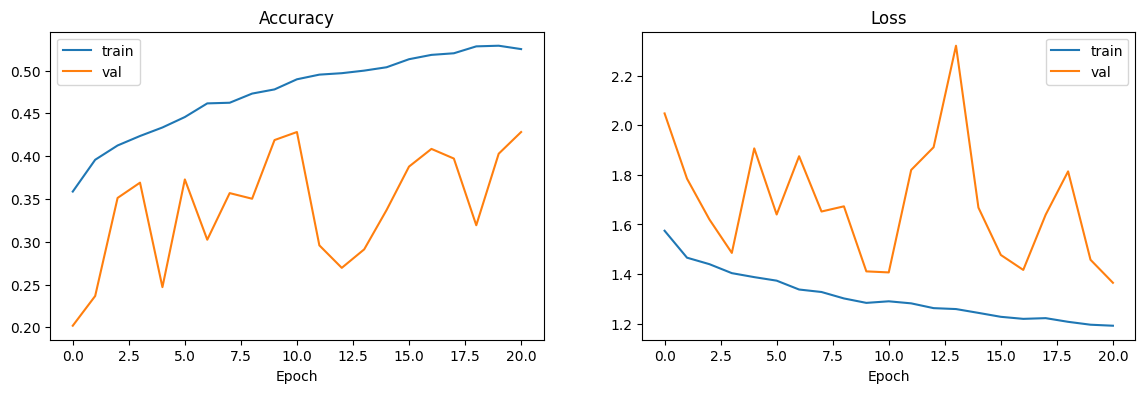

In [ ]:
import matplotlib.pyplot as plt

h = history.history
print("Best val accuracy:", round(max(h["val_accuracy"]) * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="val")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(h["loss"], label="train"); axes[1].plot(h["val_loss"], label="val")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.show()

In [5]:
import keras
from tensorflow.keras import layers, models

@keras.saving.register_keras_serializable()
class SpecAugment(layers.Layer):
    def __init__(self, freq_mask=15, time_mask=35, n_freq=2, n_time=2, **kw):
        super().__init__(**kw)
        self.freq_mask, self.time_mask = freq_mask, time_mask
        self.n_freq, self.n_time = n_freq, n_time

    def _mask(self, x, axis, max_w, n):
        size, batch = tf.shape(x)[axis], tf.shape(x)[0]
        idx = tf.range(size)[None, :]
        keep = tf.ones([batch, size], dtype=tf.bool)
        for _ in range(n):
            w = tf.random.uniform([batch, 1], 0, max_w + 1, dtype=tf.int32)
            s = tf.random.uniform([batch, 1], 0, size, dtype=tf.int32)
            keep &= ~((idx >= s) & (idx < s + w))
        keep = tf.cast(keep, x.dtype)
        return x * (keep[:, :, None, None] if axis == 1 else keep[:, None, :, None])

    def call(self, x, training=None):
        if not training:
            return x
        x = self._mask(x, 1, self.freq_mask, self.n_freq)
        return self._mask(x, 2, self.time_mask, self.n_time)

    def get_config(self):
        return {**super().get_config(), "freq_mask": self.freq_mask, "time_mask": self.time_mask,
                "n_freq": self.n_freq, "n_time": self.n_time}

inputs = layers.Input(shape=(128, 351, 1))
x = SpecAugment()(inputs)
x = conv_block(x, 32)
x = conv_block(x, 64)
x = conv_block(x, 128)
x = conv_block(x, 256)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(6, activation="softmax")(x)

cnn_aug = models.Model(inputs, outputs, name="cnn_specaug")
cnn_aug.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
cnn_aug.summary()

Model: "cnn_specaug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 351, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spec_augment (SpecAugment)      │ (None, 128, 351, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 351, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 351, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 128, 351, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 175, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64, 175, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 175, 64)    │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 175, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 175, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 87, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32, 87, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 87, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 87, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 87, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 43, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16, 43, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 43, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 43, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 16, 43, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 21, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 8, 21, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             

 Total params: 390,822 (1.49 MB)

 Trainable params: 389,862 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
callbacks_aug = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/cnn_specaug_best.keras",
                                       monitor="val_accuracy", save_best_only=True),
]

history_aug = cnn_aug.fit(X_train, y_train,
                          validation_data=(X_val, y_val),
                          epochs=80, batch_size=32,
                          callbacks=callbacks_aug)

Epoch 1/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 34s 129ms/step - accuracy: 0.3340 - loss: 1.5938 - val_accuracy: 0.2347 - val_loss: 1.7352 - learning_rate: 0.0010
Epoch 2/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.3757 - loss: 1.5040 - val_accuracy: 0.3775 - val_loss: 1.5630 - learning_rate: 0.0010
Epoch 3/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.3952 - loss: 1.4636 - val_accuracy: 0.2977 - val_loss: 1.8825 - learning_rate: 0.0010
Epoch 4/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.4145 - loss: 1.4356 - val_accuracy: 0.3324 - val_loss: 1.9308 - learning_rate: 0.0010
Epoch 5/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.4177 - loss: 1.4193 - val_accuracy: 0.3972 - val_loss: 1.6956 - learning_rate: 0.0010
Epoch 6/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.4211 - loss: 1.3992 - val_accuracy: 0.2864 - val_loss: 1.8984 - learning_rate: 0.0010
Epoch 7/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.4354 - 

In [6]:
X_ns = np.load(f"{PROJECT_DIR}/logmel_X_noscale.npy")
stats_ns = np.load(f"{PROJECT_DIR}/norm_stats_noscale.npz")
mean_ns, std_ns = stats_ns["mean"], stats_ns["std"]

def get_split_ns(name):
    idx = np.where(data["split"] == name)[0]
    x = (X_ns[idx].astype(np.float32) - mean_ns[None, :, None]) / std_ns[None, :, None]
    return x[..., None], data["label"].values[idx]

Xn_train, yn_train = get_split_ns("train")
Xn_val,   yn_val   = get_split_ns("val")
Xn_test,  yn_test  = get_split_ns("test")
Xn_rav,   yn_rav   = get_split_ns("ravdess_test")
print(Xn_train.shape, Xn_val.shape, Xn_test.shape, Xn_rav.shape)

(5329, 128, 351, 1) (1065, 128, 351, 1) (1048, 128, 351, 1) (1056, 128, 351, 1)


In [7]:
MODEL_DIR = f"{PROJECT_DIR}/models"

def build_cnn_aug(name):
    inputs = layers.Input(shape=(128, 351, 1))
    x = SpecAugment()(inputs)
    for f in [32, 64, 128, 256]:
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(6, activation="softmax")(x)
    m = models.Model(inputs, outputs, name=name)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

cnn_ns = build_cnn_aug("cnn_specaug_noscale")

callbacks_ns = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/cnn_specaug_noscale_best.keras",
                                       monitor="val_accuracy", save_best_only=True),
]

history_ns = cnn_ns.fit(Xn_train, yn_train,
                        validation_data=(Xn_val, yn_val),
                        epochs=80, batch_size=32,
                        callbacks=callbacks_ns)

Epoch 1/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 63s 216ms/step - accuracy: 0.3564 - loss: 1.5611 - val_accuracy: 0.1700 - val_loss: 2.4771 - learning_rate: 0.0010
Epoch 2/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.3890 - loss: 1.4814 - val_accuracy: 0.2263 - val_loss: 2.1573 - learning_rate: 0.0010
Epoch 3/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.3991 - loss: 1.4561 - val_accuracy: 0.3662 - val_loss: 1.5159 - learning_rate: 0.0010
Epoch 4/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.4068 - loss: 1.4418 - val_accuracy: 0.3775 - val_loss: 1.5657 - learning_rate: 0.0010
Epoch 5/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.4185 - loss: 1.4169 - val_accuracy: 0.2779 - val_loss: 1.9754 - learning_rate: 0.0010
Epoch 6/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.4307 - loss: 1.4081 - val_accuracy: 0.3484 - val_loss: 1.6025 - learning_rate: 0.0010
Epoch 7/80
167/167 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.4355 - 

In [8]:
import keras

runs = [("CNN",                                  "cnn_best.keras",                 X_val,  y_val,  X_rav,  y_rav),
        ("CNN + SpecAugment",                    "cnn_specaug_best.keras",         X_val,  y_val,  X_rav,  y_rav),
        ("CNN + SpecAugment, no volume scaling", "cnn_specaug_noscale_best.keras", Xn_val, yn_val, Xn_rav, yn_rav)]

for name, fname, xv, yv, xr, yr in runs:
    m = keras.models.load_model(f"{MODEL_DIR}/{fname}")
    val_acc = m.evaluate(xv, yv, verbose=0)[1]
    rav_acc = m.evaluate(xr, yr, verbose=0)[1]
    print(f"{name:38s} val: {val_acc*100:5.1f}%  |  RAVDESS: {rav_acc*100:5.1f}%")

CNN                                    val:  42.8%  |  RAVDESS:  18.7%
CNN + SpecAugment                      val:  47.4%  |  RAVDESS:  24.2%
CNN + SpecAugment, no volume scaling   val:  45.9%  |  RAVDESS:  31.2%
